# Student Dataset

### Generating Personalized Random Seed
#### (Importing necessary libraries)

In [1]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
username = "ritama.sanyal" 
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print(seed)

rng = np.random.default_rng(seed)
print(rng.integers(0, 100, size=5))

284869898
[18 15 88 55 40]


### DATASET GENERATION

In [2]:
class StudentDataset:
    def __init__(self, num_students: int, seed: int, username: str):
        """
        Initializes the dataset generation process.
        Saves the number of students, seed, and username.
        Sets up a reproducible random generator (rng).
        Immediately generates a dataset and stores it in self.dataframe
        """
        self.num_students = num_students
        self.seed = seed
        self.username = username
        self.rng = np.random.default_rng(seed)
        self.dataframe = self.assemble_dataframe()

    # --- Data Generation Methods (from Q1.0) ---
    def generate_gender(self) -> list[str]:
        """
        Generates a list of genders for the students.
        """
        genders = ['Male', 'Female', 'Other']
        probabilities = [0.65, 0.33, 0.02]
        return self.rng.choice(genders, self.num_students, p=probabilities)

    def generate_major(self) -> list[str]:
        """
        Generates a list of majors for the students.
        """
        majors = ['B.Tech', 'MS', 'PhD']
        probabilities = [0.70, 0.20, 0.10]
        return self.rng.choice(majors, self.num_students, p=probabilities)

    def generate_program(self, majors: list[str]) -> list[str]:
        """
        Generates a list of programs based on the students' majors.
        """
        program_probabilities = {
            'B.Tech': {'CSE': 0.40, 'ECE': 0.40, 'CHD': 0.10, 'CND': 0.10},
            'MS': {'CSE': 0.30, 'ECE': 0.30, 'CHD': 0.20, 'CND': 0.20},
            'PhD': {'CSE': 0.25, 'ECE': 0.25, 'CHD': 0.25, 'CND': 0.25}
        }
        programs = []
        for major in majors:
            programs.append(self.rng.choice(list(program_probabilities[major].keys()), p=list(program_probabilities[major].values())))
        return programs

    def generate_gpa(self, majors: list[str]) -> list[float]:
        """
        Generates a list of GPAs based on the students' majors.
        """
        gpa_distributions = {
            'B.Tech': {'mean': 7.0, 'std': 1.0},
            'MS': {'mean': 8.0, 'std': 0.7},
            'PhD': {'mean': 8.3, 'std': 0.5}
        }
        gpas = []
        for major in majors:
            mean = gpa_distributions[major]['mean']
            std = gpa_distributions[major]['std']
            gpa = self.rng.normal(mean, std)
            gpas.append(np.clip(gpa, 4.0, 10.0))
        return gpas

    def assemble_dataframe(self) -> pd.DataFrame:
        """
        Assembles the complete student dataset into a pandas DataFrame.
        """
        genders = self.generate_gender()
        majors = self.generate_major()
        programs = self.generate_program(majors)
        gpas = self.generate_gpa(majors)

        return pd.DataFrame({
            'gender': genders,
            'major': majors,
            'program': programs,
            'gpa': gpas
        })

    def get_full_dataframe(self) -> pd.DataFrame:
        """
        Returns the generated student dataset.
        """
        return self.dataframe

    def _add_username_to_plot(self, ax):
        ax.text(0.95, 0.95, self.username,
                ha='right', va='top',
                transform=ax.transAxes,
                fontsize=10, color='gray', alpha=0.7)

    # --- Q1.1 (a) Visualization Methods ---
    def plot_gender_distribution(self) -> None:
        """Plots the distribution of genders."""
        plt.figure(figsize=(8, 6))
        ax = sns.countplot(data=self.dataframe, x='gender', order=['Male', 'Female', 'Other'])
        ax.set_title('Distribution of Gender')
        ax.set_xlabel('Gender')
        ax.set_ylabel('Count')
        self._add_username_to_plot(ax)
        plt.show()

    def plot_major_distribution(self) -> None:
        """Plots the distribution of majors."""
        plt.figure(figsize=(8, 6))
        ax = sns.countplot(data=self.dataframe, x='major', order=['B.Tech', 'MS', 'PhD'])
        ax.set_title('Distribution of Major')
        ax.set_xlabel('Major')
        ax.set_ylabel('Count')
        self._add_username_to_plot(ax)
        plt.show()

    def plot_program_distribution(self) -> None:
        """Plots the overall distribution of programs."""
        plt.figure(figsize=(8, 6))
        ax = sns.countplot(data=self.dataframe, x='program', order=['CSE', 'ECE', 'CHD', 'CND'])
        ax.set_title('Distribution of Program')
        ax.set_xlabel('Program')
        ax.set_ylabel('Count')
        self._add_username_to_plot(ax)
        plt.show()

    def plot_gpa_distribution(self, bins: int = 20) -> None:
        """Plots the distribution of GPA."""
        plt.figure(figsize=(10, 6))
        ax = sns.histplot(data=self.dataframe, x='gpa', bins=bins, kde=True)
        ax.set_title('Distribution of GPA')
        ax.set_xlabel('GPA')
        ax.set_ylabel('Frequency')
        self._add_username_to_plot(ax)
        plt.show()
        
    def plot_program_by_major(self) -> None:
        """Plots the distribution of programs, conditioned on major."""
        plt.figure(figsize=(12, 7))
        ax = sns.countplot(data=self.dataframe, x='major', hue='program', 
                           order=['B.Tech', 'MS', 'PhD'], hue_order=['CSE', 'ECE', 'CHD', 'CND'])
        ax.set_title('Program Distribution by Major')
        ax.set_xlabel('Major')
        ax.set_ylabel('Count')
        ax.legend(title='Program')
        self._add_username_to_plot(ax)
        plt.show()

    def plot_gpa_by_major(self) -> None:
        """Plots the distribution of GPA, conditioned on major."""
        plt.figure(figsize=(10, 7))
        ax = sns.boxplot(data=self.dataframe, x='major', y='gpa', order=['B.Tech', 'MS', 'PhD'])
        ax.set_title('GPA Distribution by Major')
        ax.set_xlabel('Major')
        ax.set_ylabel('GPA')
        self._add_username_to_plot(ax)
        plt.show()

    def plot_gpa_by_program(self) -> None:
        """Plots the distribution of GPA, conditioned on program."""
        plt.figure(figsize=(10, 7))
        ax = sns.boxplot(data=self.dataframe, x='program', y='gpa', order=['CSE', 'ECE', 'CHD', 'CND'])
        ax.set_title('GPA Distribution by Program')
        ax.set_xlabel('Program')
        ax.set_ylabel('GPA')
        self._add_username_to_plot(ax)
        plt.show()

    def plot_gpa_by_program_and_major(self) -> None:
        """Plots GPA distribution conditioned on both program and major."""
        g = sns.catplot(data=self.dataframe, x='program', y='gpa', col='major', kind='box',
                        order=['CSE', 'ECE', 'CHD', 'CND'], col_order=['B.Tech', 'MS', 'PhD'], height=5, aspect=0.8)
        g.fig.suptitle('GPA Distribution by Program and Major', y=1.03)
        g.set_axis_labels('Program', 'GPA')
        g.set_titles("Major: {col_name}")
        # Add username to each subplot
        for ax in g.axes.flat:
            self._add_username_to_plot(ax)
        plt.show()
        
    def plot_sampled_dataset(self) -> None:
        """Plots relationships in a random sample of 100 students."""
        # Use a new random number generator for sampling to not interfere with other processes
        # But seed it from the main generator for reproducibility.
        sample_rng = np.random.default_rng(self.rng.integers(2**32))
        sampled_df = self.dataframe.sample(n=100, random_state=sample_rng)
        sampled_df.replace([np.inf, -np.inf], np.nan, inplace=True)
        g = sns.catplot(data=sampled_df, x='major', y='gpa', hue='gender', col='program', 
                        kind='swarm', col_wrap=2, height=5, aspect=1)
        g.fig.suptitle('Analysis of 100 Randomly Sampled Students', y=1.03)
        g.set_axis_labels('Major', 'GPA')
        g.set_titles("Program: {col_name}")
        # Add username to each subplot
        for ax in g.axes.flat:
            self._add_username_to_plot(ax)
        plt.tight_layout(rect=[0, 0, 1, 0.97])
        plt.show()
    def plot_entire_dataset_summary(self) -> None:
        """
        Creates a pairplot summary of the entire dataset.
        Shows relationships between GPA and categorical encodings
        of gender, program, and major, similar to seaborn's penguin example.
        """
        df = self.dataframe.copy()

        # Encode categorical columns for pairplot visualization
        df["gender_code"] = df["gender"].astype("category").cat.codes
        df["program_code"] = df["program"].astype("category").cat.codes
        df["major_code"] = df["major"].astype("category").cat.codes

        # Select subset of features for visualization
        plot_df = df[["gender_code", "program_code", "major_code", "gpa"]]

        # Pairplot with KDE on diagonal, colored by major
        g = sns.pairplot(
        data=plot_df,
        hue="major_code",
        diag_kind="kde",
        markers=["o", "s", "D"],    # different shapes for majors
        plot_kws={"alpha": 0.7, "s": 40}
        )
        g.fig.suptitle("Pairplot Summary of Student Dataset", y=1.02)

        plt.text(
        0.95, 0.95, self.username,
        ha="right", va="top",
        transform=plt.gcf().transFigure,
        fontsize=10, color="gray", alpha=0.7
        )

        plt.show()

    # --- Q1.1 (b) GPA Summary Statistics ---
    def gpa_mean_std(self) -> tuple[float, float]:
        """
        Computes the mean and standard deviation of GPA for the entire dataset.

        Returns:
            A tuple containing the mean and standard deviation of GPA.
        """
        gpa_series = self.dataframe['gpa']
        mean_gpa = gpa_series.mean()
        std_gpa = gpa_series.std()
        return (mean_gpa, std_gpa)
    
    # --- Q1.1 (c) Program Major Combinations ---
    def count_students_per_program_major_pair(self) -> pd.DataFrame:
        """
        Counts the number of students for each unique (program, major) pair.

        Returns:
            A pandas DataFrame with majors as rows and programs as columns,
            containing the student counts.
        """
        # Group by major and program and get the size of each group
        counts = self.dataframe.groupby(['major', 'program']).size()
        # Unstack the series to create a pivot-table-like DataFrame
        counts_df = counts.unstack(level='program', fill_value=0)
        return counts_df

    def visualize_students_per_program_major_pair(self, counts_df: pd.DataFrame) -> None:
        """
        Visualizes the student counts per (program, major) pair using a heatmap.

        Parameters:
            counts_df: A DataFrame containing the counts, typically from
                       the count_students_per_program_major_pair method.
        """
        plt.figure(figsize=(10, 7))
        ax = sns.heatmap(counts_df, annot=True, fmt=".4f", linewidth=.5, cmap="viridis", annot_kws={"size": 10} )
        ax.set_title('Heatmap of Student Counts per Program-Major Combination')
        ax.set_xlabel('Program')
        ax.set_ylabel('Major')
        self._add_username_to_plot(ax) 
        plt.show()

    # --- Q1.2 Simple vs Stratified Sampling ---

    def get_gpa_mean_std_random(self, n: int = 500, repeats: int = 50) -> tuple[float, float]:
        """
        Estimates the mean and std dev of GPA using simple random sampling.
    
        This method draws 'n' samples randomly, repeats the process 'repeats' times,
        and calculates the mean and standard deviation of the resulting sample means.

        Returns:
        A tuple of (mean of sample means, std dev of sample means).
        """
        sample_means = []
        for _ in range(repeats):
          sample = self.dataframe.sample(n, random_state=self.rng, replace=False)
          sample_means.append(sample['gpa'].mean())
    
        return (np.mean(sample_means), np.std(sample_means))

    def get_gpa_mean_std_stratified(self, n: int = 500, repeats: int = 50) -> tuple[float, float]:
        """
        Estimates the mean and std dev of GPA using stratified sampling by major.

        This method ensures each major is represented proportionally in the sample.
        It repeats the process 'repeats' times and calculates the mean and 
        standard deviation of the resulting sample means.

        Returns:
            A tuple of (mean of sample means, std dev of sample means).
        """
        sample_means = []
    # Get the proportions of each major in the full dataset
        major_proportions = self.dataframe['major'].value_counts(normalize=True)

        for _ in range(repeats):
            stratified_sample_parts = []
            for major, proportion in major_proportions.items():
            # Number of samples to draw from this stratum
                n_major = int(round(proportion * n))
            
            # Get the data for the current major
                major_df = self.dataframe[self.dataframe['major'] == major]
            
            # Draw the sample and add to our list
                stratified_sample_parts.append(
                    major_df.sample(n_major, random_state=self.rng, replace=False)
                )
        
            # Combine the stratified parts into one sample dataframe
            final_sample = pd.concat(stratified_sample_parts)
            sample_means.append(final_sample['gpa'].mean())
        
        return (np.mean(sample_means), np.std(sample_means))
    
    # --- Q1.3 Gender Balanced Cohort ---

    def get_gender_balanced_counts(self, n: int = 300, repeats: int = 5) -> list[dict[str, int]]:
        """
        Samples a cohort with an exact equal number of students from each gender.

        Returns:
            A list of dictionaries, where each dictionary holds the gender counts
            for one of the repeated sampling processes.
        """
        genders = self.dataframe['gender'].unique()
        n_per_gender = n // len(genders)
    
        # Check if there are enough students in the smallest category
        min_category_size = self.dataframe['gender'].value_counts().min()
        if n_per_gender > min_category_size:
            raise ValueError(f"Cannot sample {n_per_gender} students from the smallest gender category, which only has {min_category_size} students.")

        all_counts = []
        for _ in range(repeats):
            samples = [
                self.dataframe[self.dataframe['gender'] == g].sample(n_per_gender, random_state=self.rng)
                for g in genders
            ]
            combined_sample = pd.concat(samples)
            counts = combined_sample['gender'].value_counts().to_dict()
            all_counts.append(counts)
        return all_counts

    def sample_gender_uniform_random(self, n: int = 300, repeats: int = 5) -> list[dict[str, int]]:
        """
        Samples n students using "Sampling Strategy A":
        1. Uniformly pick a gender.
        2. Randomly pick a student from that gender.
        3. Repeat n times.

        Returns:
            A list of dictionaries containing the gender counts for each repeat.
        """
        genders = list(self.dataframe['gender'].unique())
        gender_dfs = {g: self.dataframe[self.dataframe['gender'] == g] for g in genders}
        all_counts = []
        for _ in range(repeats):
            student_indices = []
            for _ in range(n):
                # Step 1: Uniformly pick a gender
                chosen_gender = self.rng.choice(genders)
                # Step 2: Randomly pick a student from that gender (with replacement)
                student_indices.append(gender_dfs[chosen_gender].sample(1, random_state=self.rng).index[0])
        
            final_sample = self.dataframe.loc[student_indices]
            counts = final_sample['gender'].value_counts().to_dict()
            all_counts.append(counts)
        return all_counts

    def plot_avg_max_gender_diff_vs_sample_size(self, sample_sizes: list[int], repeats: int = 10) -> None:
        """
        Plots the average maximum relative difference in gender counts vs. sample size.
        """
        avg_diffs = []
    
        for n in sample_sizes:
            max_relative_diffs = []
            # We need to call the logic from sample_gender_uniform_random here
            temp_counts_list = self.sample_gender_uniform_random(n=n, repeats=repeats)
        
            for counts_dict in temp_counts_list:
                if len(counts_dict) > 1:
                    max_count = max(counts_dict.values())
                    min_count = min(counts_dict.values())
                    relative_diff = (max_count - min_count) / n
                    max_relative_diffs.append(relative_diff)
        
            avg_diffs.append(np.mean(max_relative_diffs))
        
        plt.figure(figsize=(10, 6))
        ax = sns.barplot(x=[str(s) for s in sample_sizes], y=avg_diffs)
        ax.set_title('Average Max Relative Gender Difference vs. Sample Size')
        ax.set_xlabel('Sample Size (n)')
        ax.set_ylabel('Avg. Max Relative Difference')
        self._add_username_to_plot(ax)
        plt.show()


    #--- Q1.4 GPA Uniform Cohort ---
    def sample_gpa_uniform(self, n: int = 100, bins: int = 10) -> pd.DataFrame:
        """
        Samples n students such that their GPAs are approximately uniformly
        distributed across a specified number of bins.

        This is achieved using Sampling Strategy A, where the "categories"
        are the GPA bins.
    
        Returns:
            A pandas DataFrame containing the sampled students.
        """
        # 1. Create GPA bins and assign each student to a bin
        df = self.dataframe.copy()
        df['gpa_bin'] = pd.cut(df['gpa'], bins=bins, labels=False, include_lowest=True)
    
        # 2. Create a list of dataframes, one for each bin
        binned_dfs = [df[df['gpa_bin'] == i] for i in range(bins)]
    
        # 3. Apply Sampling Strategy A
        sampled_indices = []
        for _ in range(n):
            # a) Uniformly pick a random bin
            chosen_bin = self.rng.choice(range(bins))
            # b) Randomly pick a student from that bin (with replacement)
            student_sample = binned_dfs[chosen_bin].sample(1, replace=True, random_state=self.rng)
            sampled_indices.append(student_sample.index[0])
        
        # 4. Return the final sample
        return self.dataframe.loc[sampled_indices]

    def plot_gpa_histogram_comparison(self, sampled_df: pd.DataFrame, bins: int = 10) -> None:
        """
        Plots the GPA histogram of a sampled dataset alongside the original dataset's
        GPA histogram for comparison.

        Parameters:
            sampled_df: The DataFrame of sampled students.
            bins: The number of bins to use for the histograms.
        """
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
        fig.suptitle('Comparison of GPA Distributions', fontsize=16)

        # Plot original distribution
        sns.histplot(self.dataframe['gpa'], bins=bins, ax=axes[0], kde=False)
        axes[0].set_title('Original Dataset')
        axes[0].set_xlabel('GPA')
        axes[0].set_ylabel('Frequency')
        self._add_username_to_plot(axes[0])

        # Plot sampled distribution
        sns.histplot(sampled_df['gpa'], bins=bins, ax=axes[1], kde=False)
        axes[1].set_title('GPA-Uniform Sampled Dataset')
        axes[1].set_xlabel('GPA')
        axes[1].set_ylabel('') 
        self._add_username_to_plot(axes[1])
    
        plt.show()

    # --- Q1.5 Program major Balanced Cohort ---

    def sample_program_major_balanced(self, n: int = 60) -> pd.DataFrame:
        """
        Samples n students such that all valid (program, major) combinations
        are represented approximately equally using Sampling Strategy A.
        
        Returns:
            A pandas DataFrame of the sampled students.
        """
        # 1. Identify all unique (program, major) combinations as our categories
        df = self.dataframe.copy()
        df['combo'] = df['major'] + '_' + df['program']
        combos = list(df['combo'].unique())
        
        # 2. Create a dictionary of dataframes, one for each combination
        combo_dfs = {c: df[df['combo'] == c] for c in combos}
        
        # 3. Apply Sampling Strategy A
        sampled_indices = []
        for _ in range(n):
            # a) Uniformly pick a random combination (category)
            chosen_combo = self.rng.choice(combos)
            # b) Randomly pick one student from that combination (with replacement)
            student_sample = combo_dfs[chosen_combo].sample(1, replace=True, random_state=self.rng)
            sampled_indices.append(student_sample.index[0])
            
        # 4. Return the final sample
        return self.dataframe.loc[sampled_indices]

    def show_program_major_counts_and_heatmap(self, sampled_df: pd.DataFrame) -> None:
        """
        Displays the counts of (program, major) pairs for a given sample
        and visualizes them with a heatmap.
        
        Parameters:
            sampled_df: The DataFrame of sampled students.
        """
        # 1. Calculate the counts
        counts = sampled_df.groupby(['major', 'program']).size().unstack(fill_value=0)
        
        print("--- Sampled Counts per Program-Major Combination ---")
        print(counts)
        
        # 2. Create the heatmap
        plt.figure(figsize=(10, 7))
        ax = sns.heatmap(counts, annot=True, fmt='d', cmap='YlGnBu')
        ax.set_title('Heatmap of Sampled Student Counts')
        ax.set_xlabel('Program')
        ax.set_ylabel('Major')
        self._add_username_to_plot(ax)
        plt.show()

In [3]:
num_students = 10000
student_data = StudentDataset(num_students, seed,username)
df = student_data.get_full_dataframe()
df.to_csv("student_dataset.csv", index=False)
print(df.head())

   gender   major program       gpa
0    Male  B.Tech     ECE  6.626908
1    Male  B.Tech     CHD  5.493780
2  Female  B.Tech     ECE  5.989387
3  Female     PhD     ECE  8.270594
4    Male  B.Tech     CHD  7.579556


### 1.1 DATASET ANALYSIS

#### (a) VISUALIZATION

--- Plotting Gender Distribution ---


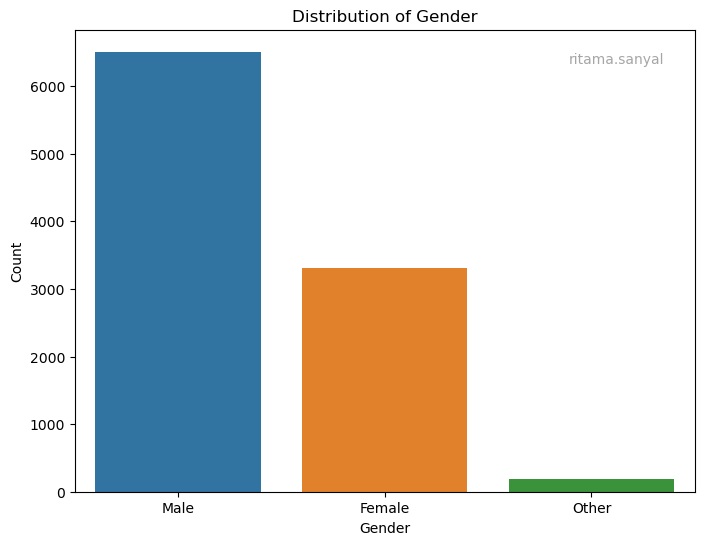


--- Plotting Major Distribution ---


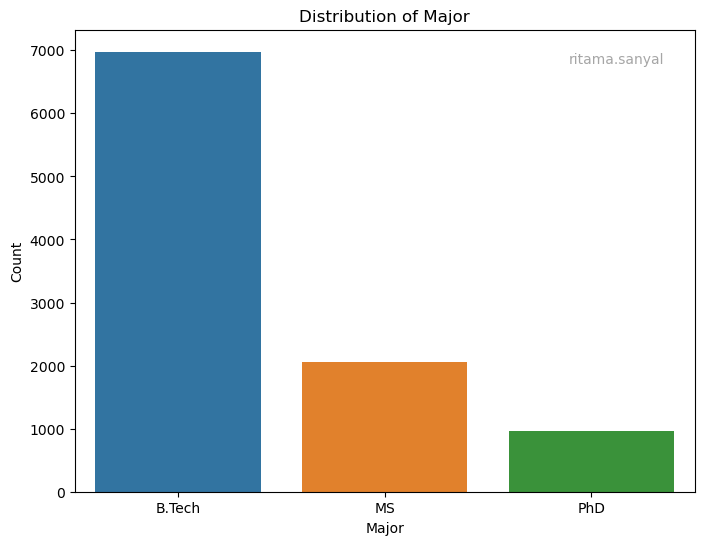


--- Plotting Program Distribution ---


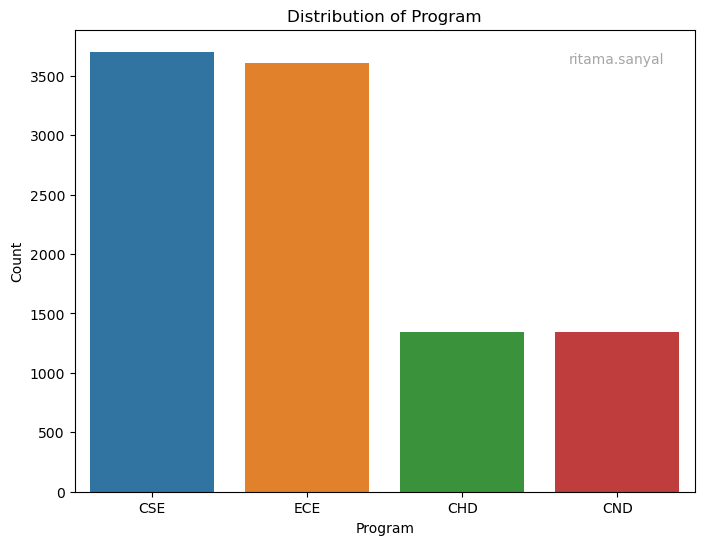


--- Plotting GPA Distribution ---


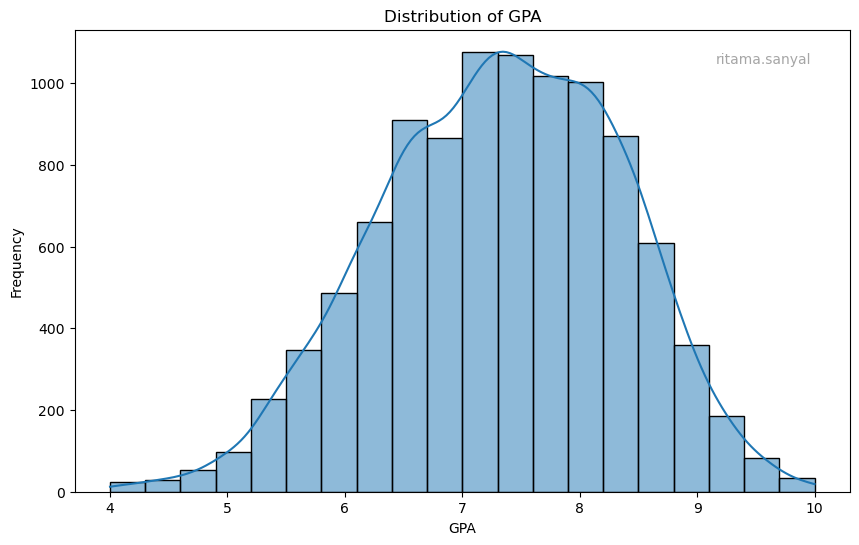


--- Plotting Program conditioned on Major ---


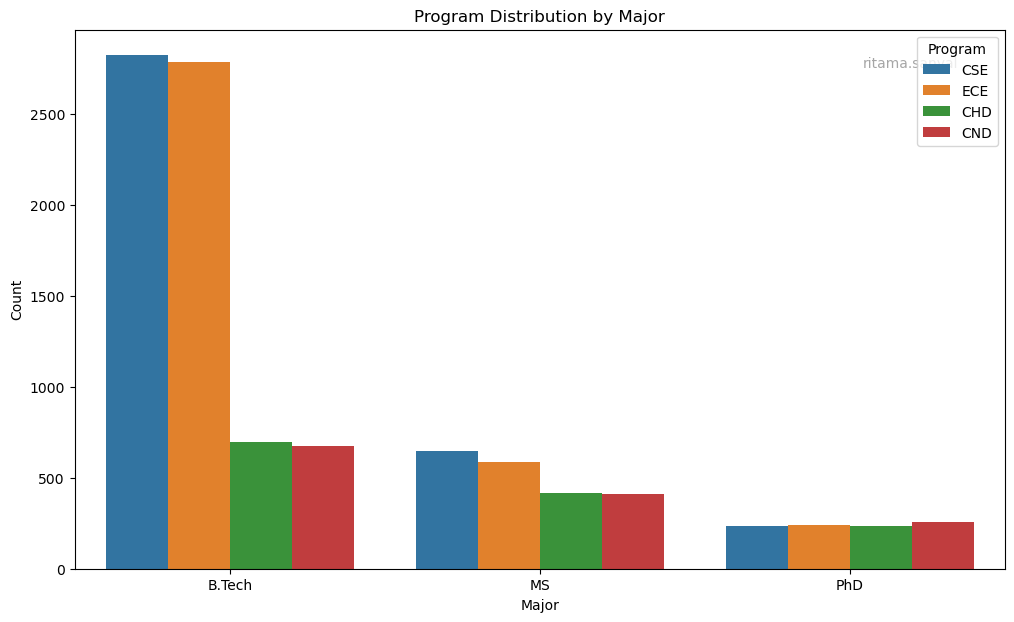


--- Plotting GPA conditioned on Major ---


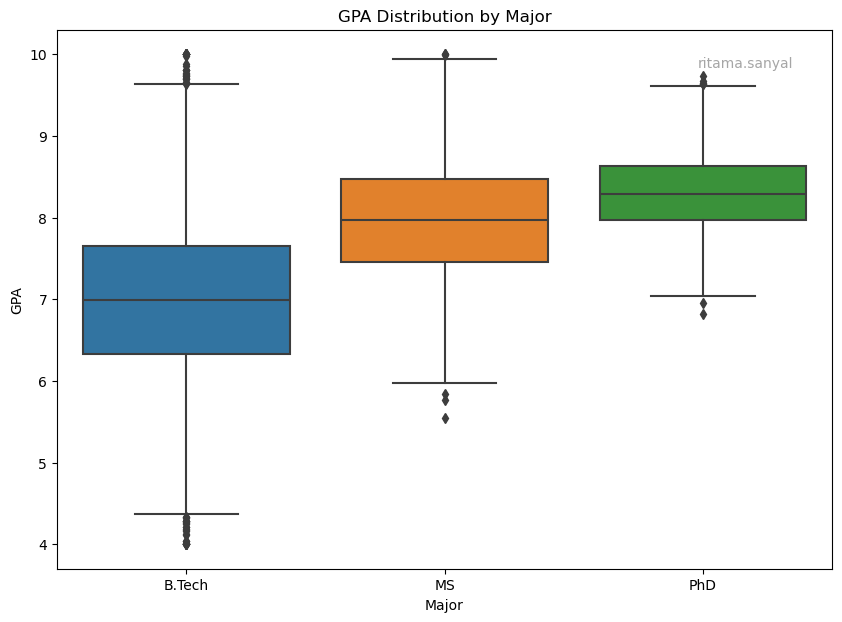


--- Plotting GPA conditioned on Program ---


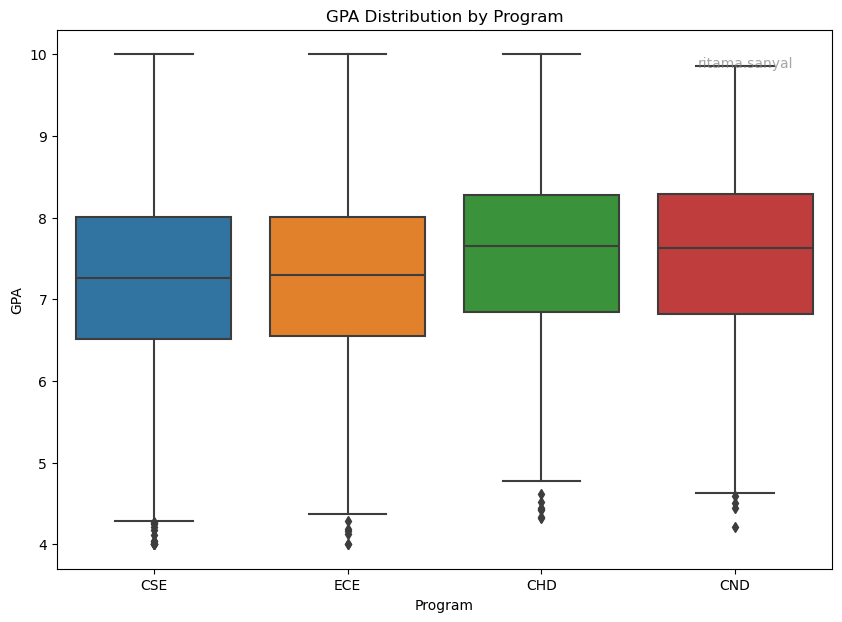


--- Plotting GPA conditioned on Program and Major ---


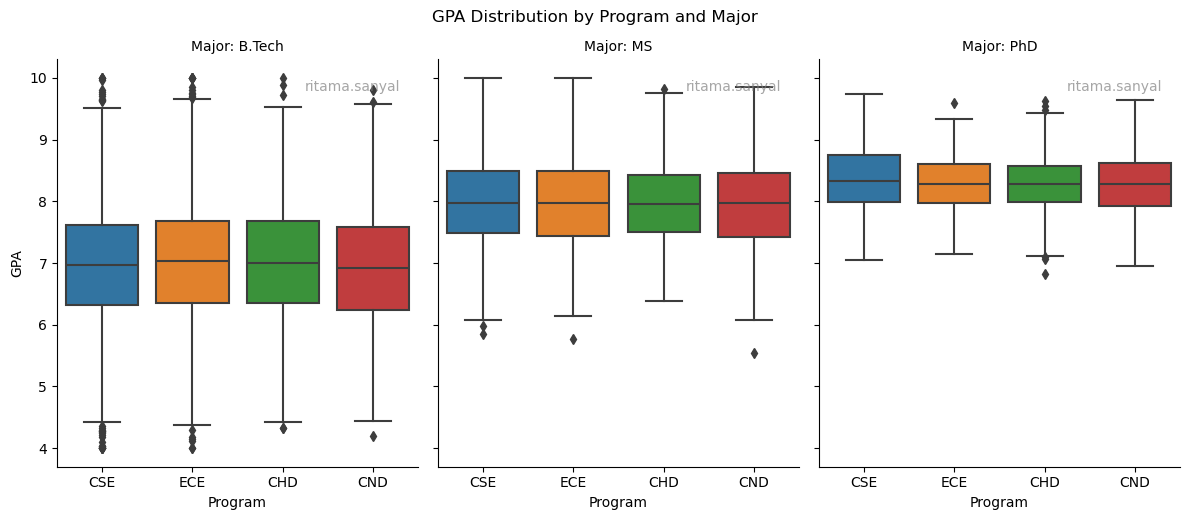


--- Plotting Summary of 100 Randomly Sampled Students ---


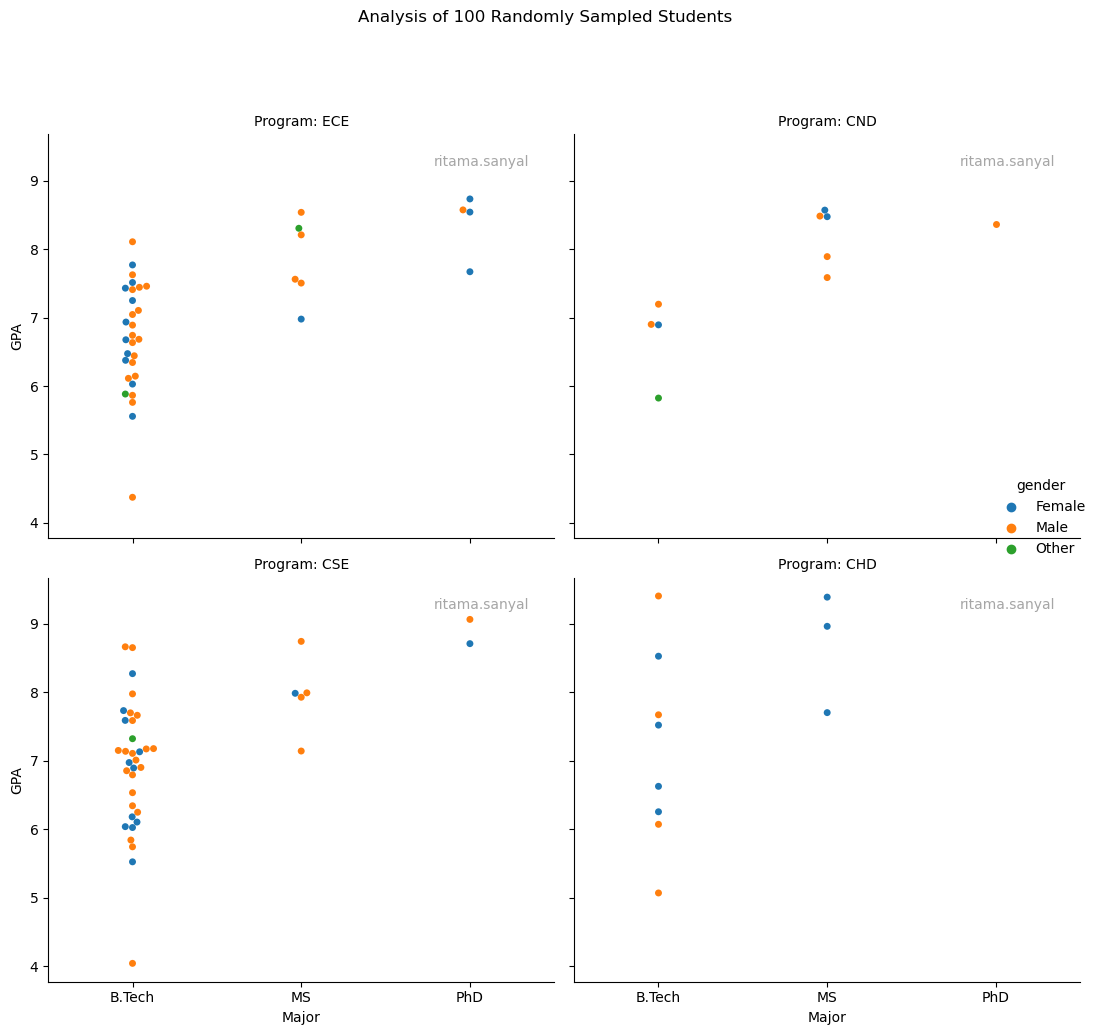


--- Plotting Summary of Entire Dataset ---


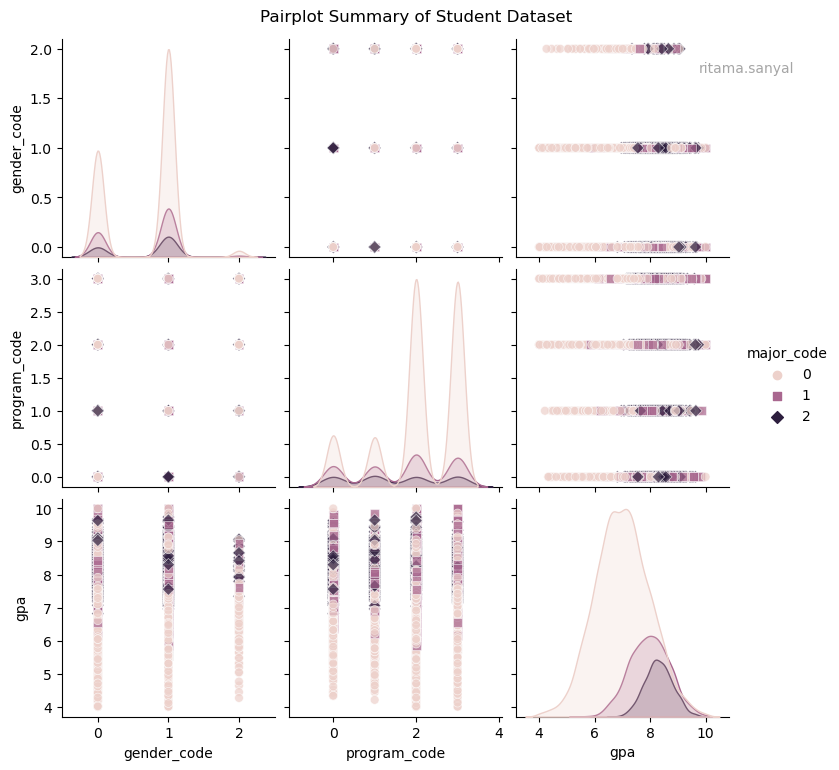

In [4]:
print("--- Plotting Gender Distribution ---")
student_data.plot_gender_distribution()

print("\n--- Plotting Major Distribution ---")
student_data.plot_major_distribution()

print("\n--- Plotting Program Distribution ---")
student_data.plot_program_distribution()

print("\n--- Plotting GPA Distribution ---")
student_data.plot_gpa_distribution()

print("\n--- Plotting Program conditioned on Major ---")
student_data.plot_program_by_major()

print("\n--- Plotting GPA conditioned on Major ---")
student_data.plot_gpa_by_major()

print("\n--- Plotting GPA conditioned on Program ---")
student_data.plot_gpa_by_program()

print("\n--- Plotting GPA conditioned on Program and Major ---")
student_data.plot_gpa_by_program_and_major()

print("\n--- Plotting Summary of 100 Randomly Sampled Students ---")
student_data.plot_sampled_dataset()

print("\n--- Plotting Summary of Entire Dataset ---")
warnings.filterwarnings("ignore", category=FutureWarning)
student_data.plot_entire_dataset_summary()

major_code

0 → B.Tech

1 → MS

2 → PhD

gender_code

0 → Female

1 → Male

2 → Other

program_code

0 → CHD

1 → CND

2 → CSE

3 → ECE

🔹 What the plot shows

The plot matrix compares gender_code, program_code, and GPA, with points colored by major_code.

Diagonal plots (KDEs):

Gender_code: Tallest peak at 1 (Male), smaller at 0 (Female), tiny at 2 (Other) → matches the 65%-33%-2% distribution.

Program_code: Four clear peaks (CHD, CND, CSE, ECE), consistent with how program distribution depends on major.

GPA:

B.Tech (major_code=0): distribution centered around ~7, wide spread.

MS (1): distribution centered near 8, narrower spread.

PhD (2): distribution around 8.3, very tight.

Scatterplots off the diagonal:

Gender vs GPA: GPA spread looks similar for male and female, but PhD students consistently cluster at higher GPA regardless of gender.

Program vs GPA:

B.Tech (0) → mostly in CSE and ECE, GPA wider.

MS (1) → present in all programs, GPA higher and tighter.

PhD (2) → evenly spread across all programs, GPAs high and consistent.

Gender vs Program:

Male dominance is visible across all programs.

Female students present in all programs, though fewer.

“Other” category tiny across programs.

#### (b) GPA SUMMARY STATISTICS


In [5]:
mean_gpa, std_gpa = student_data.gpa_mean_std()

print("Overall GPA Summary Statistics:")
print(f"Mean GPA: {mean_gpa:.4f}")
print(f"Standard Deviation of GPA: {std_gpa:.4f}")

Overall GPA Summary Statistics:
Mean GPA: 7.3222
Standard Deviation of GPA: 1.0266


The average GPA of ~7.32 indicates that most students are performing at a fairly good level (well above the minimum of 4.0, closer to the mid-to-high range).

The standard deviation of ~1.03 suggests moderate variability in student performance:

Most GPAs are clustered within the range 6.3 – 8.3 (mean ± 1 std).

This means the dataset does not show extreme spread — GPAs are relatively consistent across students.

Given the clipping of GPA values between 4.0 and 10.0, the distribution is likely slightly left-skewed, since very low GPAs are impossible while high GPAs (close to 10.0) are still achievable.

#### (c) PROGRAM MAJOR COMBINATIONS

--- Student Counts for each (Program, Major) Combination ---
program  CHD  CND   CSE   ECE
major                        
B.Tech   698  673  2821  2785
MS       415  408   648   584
PhD      235  259   233   241

--- Heatmap Visualization ---


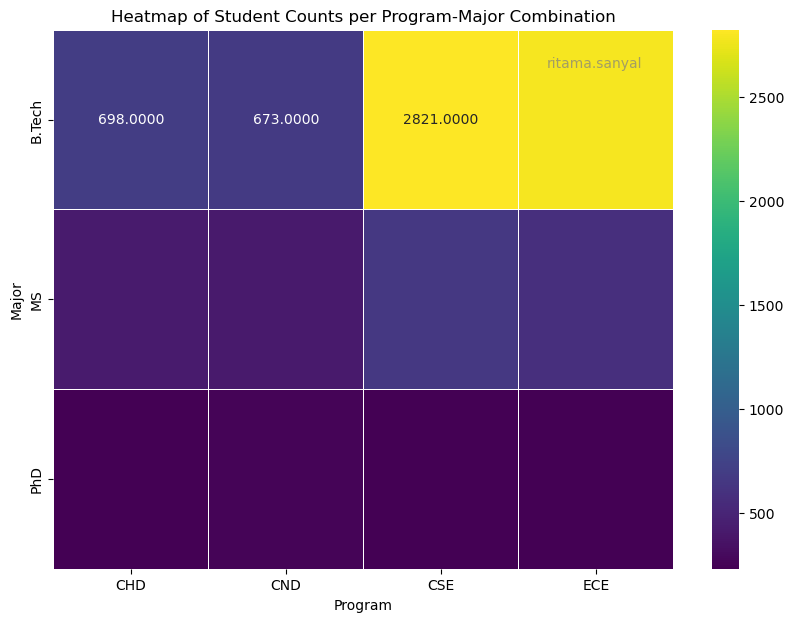

In [6]:
# 1. Get the counts DataFrame
program_major_counts = student_data.count_students_per_program_major_pair()

# 2. Report the counts by printing the DataFrame
print("--- Student Counts for each (Program, Major) Combination ---")
print(program_major_counts)

# 3. Visualize the counts with a heatmap
print("\n--- Heatmap Visualization ---")
student_data.visualize_students_per_program_major_pair(program_major_counts)

B.Tech dominates overall:

Very high counts in CSE (2821) and ECE (2785), much larger than MS/PhD levels.

CHD and CND are much smaller (~670 each) compared to core technical branches.

MS programs are more balanced:

Counts are smaller (400–650 per program), but distribution across CSE, ECE, CHD, and CND is fairly even.

This suggests that specialization diversity is higher in MS.

PhD programs are the most balanced:

Each program (CSE, ECE, CHD, CND) has around ~230–260 students.

Indicates equal distribution among research fields.

Overall Trend:

CSE and ECE dominate at the undergraduate (B.Tech) level.

CHD and CND attract fewer B.Tech students but maintain consistent presence at MS and PhD.

At higher degrees, students spread more evenly across programs.

### 1.2 SIMPLE VS STRATIFIED SAMPLING

In [7]:
# Run Simple Random Sampling
mean_random, std_random = student_data.get_gpa_mean_std_random()
print("--- Simple Random Sampling Results ---")
print(f"Mean of Sample Means: {mean_random:.4f}")
print(f"Standard Deviation of Sample Means: {std_random:.4f}\n")

# Run Stratified Sampling
mean_stratified, std_stratified = student_data.get_gpa_mean_std_stratified()
print("--- Stratified Sampling Results ---")
print(f"Mean of Sample Means: {mean_stratified:.4f}")
print(f"Standard Deviation of Sample Means: {std_stratified:.4f}")

--- Simple Random Sampling Results ---
Mean of Sample Means: 7.3097
Standard Deviation of Sample Means: 0.0445

--- Stratified Sampling Results ---
Mean of Sample Means: 7.3206
Standard Deviation of Sample Means: 0.0413


Stratified sampling has a lower standard deviation because it **reduces variability** in the sample means.  

**1. Controlling for a Key Variable:**  
We already know that a student’s **major** has a significant impact on GPA.  
- B.Tech, MS, and PhD students all have different GPA distributions.  

**2. Problem with Simple Random Sampling:**  
In simple random sampling, chance alone can lead to unbalanced samples:  
- A sample might include too many PhD students, inflating the mean GPA.  
- Another might over-represent B.Tech students, deflating the mean GPA.  
This randomness increases the **variability** (standard deviation) of the sample means.  

**3. Advantage of Stratified Sampling:**  
Stratified sampling ensures each sample mirrors the **population’s major proportions**.  
- Each sample has B.Tech, MS, and PhD students in the correct ratio.  
- This consistency removes variability caused by uneven representation.  

**4.Result:**  
- Every stratified sample is a more accurate miniature of the population.  
- Sample means are more consistent → **lower standard deviation**.  


### 1.3 GENDER BASED COHORT

In [8]:
print("--- Method 1: Exactly Balanced Gender Counts ---")
balanced_counts = student_data.get_gender_balanced_counts()
for i, counts in enumerate(balanced_counts):
    print(f"Repeat {i+1}: {counts}")

--- Method 1: Exactly Balanced Gender Counts ---
Repeat 1: {'Male': 100, 'Female': 100, 'Other': 100}
Repeat 2: {'Male': 100, 'Female': 100, 'Other': 100}
Repeat 3: {'Male': 100, 'Female': 100, 'Other': 100}
Repeat 4: {'Male': 100, 'Female': 100, 'Other': 100}
Repeat 5: {'Male': 100, 'Female': 100, 'Other': 100}


In [9]:
print("\n--- Method 2: Sampling Strategy A Counts ---")
strategy_A_counts = student_data.sample_gender_uniform_random()
for i, counts in enumerate(strategy_A_counts):
    print(f"Repeat {i+1}: {counts}")


--- Method 2: Sampling Strategy A Counts ---
Repeat 1: {'Female': 110, 'Male': 105, 'Other': 85}
Repeat 2: {'Other': 103, 'Male': 101, 'Female': 96}
Repeat 3: {'Male': 112, 'Other': 94, 'Female': 94}
Repeat 4: {'Other': 107, 'Female': 105, 'Male': 88}
Repeat 5: {'Other': 103, 'Male': 102, 'Female': 95}



--- Method 3: Plotting Imbalance vs. Sample Size ---


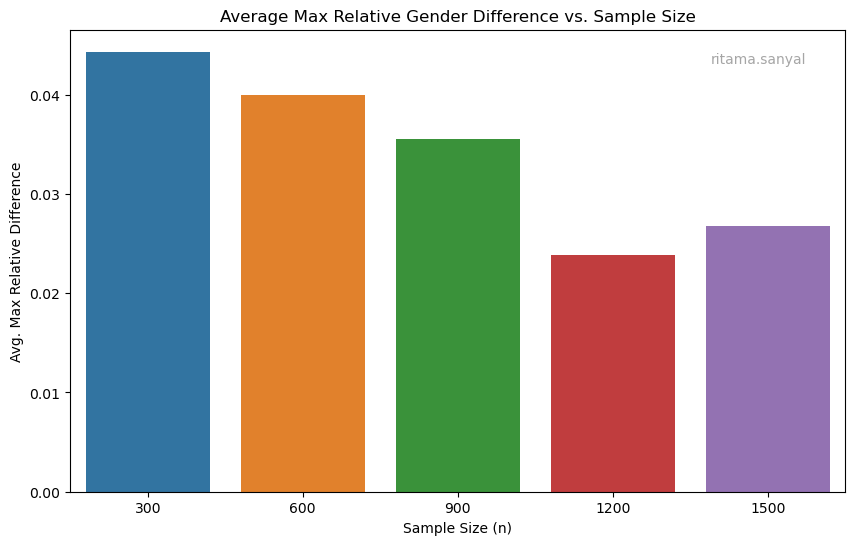

In [10]:
print("\n--- Method 3: Plotting Imbalance vs. Sample Size ---")
sample_sizes = [300, 600, 900, 1200, 1500]
student_data.plot_avg_max_gender_diff_vs_sample_size(sample_sizes=sample_sizes)

### 1.4 GPA UNIFORM COHORT

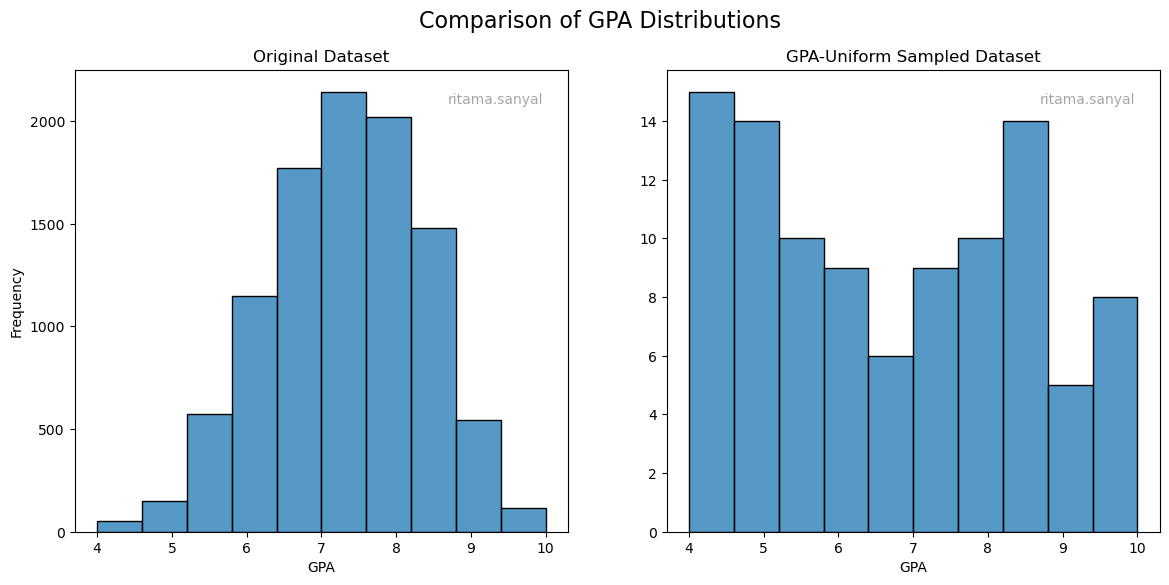

In [11]:
# 1. Generate the GPA-uniform sample
gpa_uniform_sample = student_data.sample_gpa_uniform()
# 2. Plot the comparison histograms
student_data.plot_gpa_histogram_comparison(gpa_uniform_sample)

### Analysis of the Plot

- **Original GPA Distribution (left):**  
  The histogram shows the full dataset’s GPA distribution, which appears **multi-modal (lumpy)**.  
  This happens because the population is a mixture of three normal distributions (B.Tech, MS, PhD).  

- **Uniform-Sampled GPA Distribution (right):**  
  The histogram from the sampled cohort is noticeably **flatter and more uniform**.  
  This demonstrates that **Sampling Strategy A** successfully created a cohort where GPAs are more evenly spread across the entire range.

---

### Did you sample with or without replacement? Why? 

I sampled **with replacement**, for three key reasons:

1. **Robustness**  
   - Some GPA bins may naturally contain very few students.  
   - Without replacement, we could run out of students in sparse bins, making it impossible to keep sampling from them.  
   - With replacement, we can always draw from any bin, no matter how small.  

2. **Maintaining an Unchanged Distribution**  
   - The goal is to repeatedly draw from 10 conceptual GPA bins.  
   - Sampling *with* replacement ensures that the underlying distribution of each bin **stays constant** across draws.  
   - Without replacement, the distribution within each bin would change after every draw, complicating the process.  

3. **Simplicity**  
   - With replacement, the procedure directly mirrors the idea of Sampling Strategy A.  
   - It provides a **clean and consistent implementation** where the focus is on the distribution across bins, not on ensuring uniqueness of students.

---

 **Conclusion:**  
Sampling with replacement ensures robustness, preserves the intended distributions, and simplifies the implementation, making it the appropriate choice for this task.


### 1.5 PROGRAM MAJOR BALANCED COHORT

--- Sampled Counts per Program-Major Combination ---
program  CHD  CND  CSE  ECE
major                      
B.Tech     2    2   10    7
MS         2    5    5    5
PhD        4   10    2    6


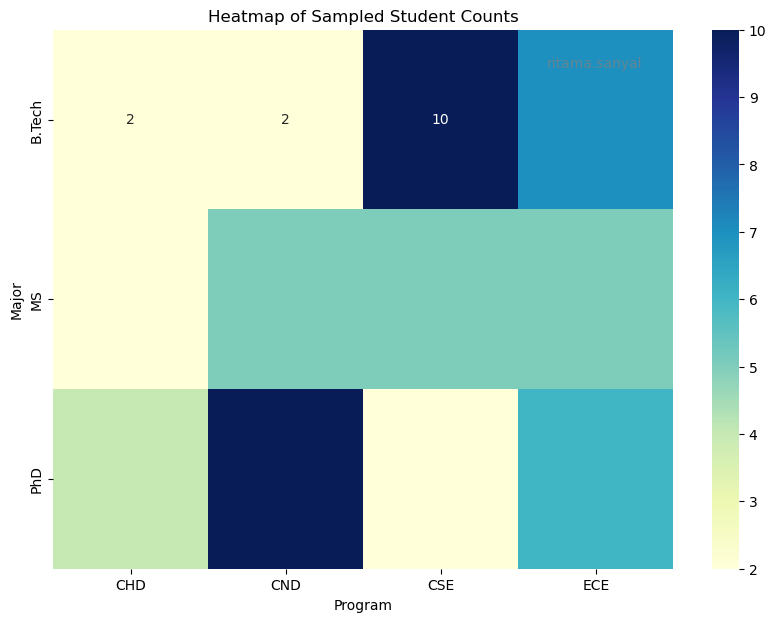

In [12]:
# 1. Generate the program-major balanced sample
balanced_sample = student_data.sample_program_major_balanced(n=60)

# 2. Show the counts and heatmap
student_data.show_program_major_counts_and_heatmap(balanced_sample)

### Analysis of Results

- The **printed table** and the **heatmap** show the counts for each of the 12 possible (program, major) combinations.  
- Since we sampled **60 students** and there are **12 categories**, the **ideal count per cell** is:  

60/12 = 5


- The observed counts fluctuate around 5, which confirms that **Sampling Strategy A** produced a cohort with **approximately equal representation** from each program-major combination.  

---

### Were any groups too small? How did you handle it? 

Yes, some (program, major) combinations had very small counts in the sampled dataset:

B.Tech – CHD → 2 students

MS – CHD → 2 students

PhD – CSE → 2 students

These are much smaller than combinations like B.Tech – CSE (10) or PhD – ECE (6).

Handling small groups with replacement:

Because some groups were too small to reach the ideal equal representation, sampling with replacement was used.

This means students from small groups could be sampled more than once, allowing each (program, major) combination to contribute approximately equally to the total sample of 60.

Larger groups were sampled proportionally as well, maintaining overall balance.

Key Takeaways:

Replacement allows small groups to be represented adequately without being limited by their original size.

All (program, major) pairs are included, ensuring complete representation.

The resulting sample maintains approximate equality while respecting the constraints of small groups.


https://g.co/gemini/share/cb829e9b6535 <br>
https://chatgpt.com/share/68aded89-4ca8-800c-a7db-df9375e800f7 <br>
https://chatgpt.com/share/68adeda1-18a8-800c-865d-7a9362ff73e9